In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ttest_ind, wilcoxon
import numpy as np
import os

In [ ]:
tasks_all = pd.read_csv("/Users/ferolahima/Desktop/gazepoint_project/Export-Video Mappings.xlsx - Foglio1.csv")
fixations_df = pd.read_csv("outputs/fixations_all_rows.csv")
gaze_df      = pd.read_csv("outputs/gaze_all_rows.csv")
# 1) Prepare task intervals
tasks = tasks_all.rename(columns={
    "Video Name": "Video Name (folder)",
    "User ID": "User ID (file)",
    "Starting time in seconds": "t_start",
    "Finishing time in seconds": "t_end",
}).copy()

tasks["Task Id"] = tasks["Task Id"].astype(str)
fixations_df["Task Id"] = fixations_df["Task Id"].astype(str)
gaze_df["Task Id"]      = gaze_df["Task Id"].astype(str)

# 2) Merge interval bounds onto rows (for ON detection)
fix_m = fixations_df.merge(
    tasks[["Video Name (folder)","User ID (file)","Task Id","t_start","t_end"]],
    on=["Video Name (folder)","User ID (file)","Task Id"], how="left"
)
gaz_m = gaze_df.merge(
    tasks[["Video Name (folder)","User ID (file)","Task Id","t_start","t_end"]],
    on=["Video Name (folder)","User ID (file)","Task Id"], how="left"
)

# 3) Initialize labels
fix_m["label"] = "UNLABELED"
gaz_m["label"] = "UNLABELED"

# 4) ON = inside [start, end]
fix_on = fix_m["TIME"].between(fix_m["t_start"], fix_m["t_end"], inclusive="both")
gaz_on = gaz_m["TIME"].between(gaz_m["t_start"], gaz_m["t_end"], inclusive="both")
fix_m.loc[fix_on, "label"] = "ON"
gaz_m.loc[gaz_on, "label"] = "ON"

# 5) OFF = in [start-3, start), but do NOT overwrite ON
def apply_off_labels(df, tasks):
    # Work per (video,user) for speed and clarity
    for (vn, uid), tgrp in tasks.groupby(["Video Name (folder)","User ID (file)"]):
        sel = (df["Video Name (folder)"] == vn) & (df["User ID (file)"] == uid)
        if not sel.any():
            continue
        for _, r in tgrp.iterrows():
            pre_start = max(0.0, float(r.t_start) - 3.0)
            mask = sel & (df["TIME"] >= pre_start) & (df["TIME"] < r.t_start) & (df["label"] != "ON")
            df.loc[mask, "label"] = "OFF"
    return df

fix_m = apply_off_labels(fix_m, tasks)
gaz_m = apply_off_labels(gaz_m, tasks)

# 6) Keep your original columns + new label
keep_cols = list(fixations_df.columns) + ["label"]
fixations_labeled = fix_m[keep_cols].copy()
gaze_labeled      = gaz_m[list(gaze_df.columns) + ["label"]].copy()

# (optional) save
fixations_labeled.to_csv("outputs/fixations_with_on_off.csv", index=False)

function to create your on off csv

In [ ]:
tasks_all = pd.read_csv("/Users/ferolahima/Desktop/gazepoint_project/Export-Video Mappings.xlsx - Foglio1.csv")
fixations_df = pd.read_csv("outputs/fixations_all_rows.csv")
gaze_df      = pd.read_csv("outputs/gaze_all_rows.csv")
# 1) Prepare task intervals
tasks = tasks_all.rename(columns={
    "Video Name": "Video Name (folder)",
    "User ID": "User ID (file)",
    "Starting time in seconds": "t_start",
    "Finishing time in seconds": "t_end",
}).copy()

tasks["Task Id"] = tasks["Task Id"].astype(str)
fixations_df["Task Id"] = fixations_df["Task Id"].astype(str)
gaze_df["Task Id"]      = gaze_df["Task Id"].astype(str)

# 2) Merge interval bounds onto rows (for ON detection)
fix_m = fixations_df.merge(
    tasks[["Video Name (folder)","User ID (file)","Task Id","t_start","t_end"]],
    on=["Video Name (folder)","User ID (file)","Task Id"], how="left"
)
gaz_m = gaze_df.merge(
    tasks[["Video Name (folder)","User ID (file)","Task Id","t_start","t_end"]],
    on=["Video Name (folder)","User ID (file)","Task Id"], how="left"
)

# 3) Initialize labels
fix_m["label"] = "UNLABELED"
gaz_m["label"] = "UNLABELED"

# 4) ON = inside [start, end]
fix_on = fix_m["TIME"].between(fix_m["t_start"], fix_m["t_end"], inclusive="both")
gaz_on = gaz_m["TIME"].between(gaz_m["t_start"], gaz_m["t_end"], inclusive="both")
fix_m.loc[fix_on, "label"] = "ON"
gaz_m.loc[gaz_on, "label"] = "ON"

# 5) OFF = in [start-3, start), but do NOT overwrite ON
def apply_off_labels(df, tasks):
    # Work per (video,user) for speed and clarity
    for (vn, uid), tgrp in tasks.groupby(["Video Name (folder)","User ID (file)"]):
        sel = (df["Video Name (folder)"] == vn) & (df["User ID (file)"] == uid)
        if not sel.any():
            continue
        for _, r in tgrp.iterrows():
            pre_start = max(0.0, float(r.t_start) - 3.0)
            mask = sel & (df["TIME"] >= pre_start) & (df["TIME"] < r.t_start) & (df["label"] != "ON")
            df.loc[mask, "label"] = "OFF"
    return df

fix_m = apply_off_labels(fix_m, tasks)
gaz_m = apply_off_labels(gaz_m, tasks)

# 6) Keep your original columns + new label
keep_cols = list(fixations_df.columns) + ["label"]
fixations_labeled = fix_m[keep_cols].copy()
gaze_labeled      = gaz_m[list(gaze_df.columns) + ["label"]].copy()

# (optional) save
fixations_labeled.to_csv("outputs/fixations_with_on_off.csv", index=False)

In [2]:
fx_labeled = pd.read_csv("outputs/fixations_with_on_off.csv")
tasks_all = pd.read_csv("/Users/ferolahima/Desktop/gazepoint_project/Export-Video Mappings.xlsx - Foglio1.csv")
fixations_df = pd.read_csv("/Users/ferolahima/Desktop/gazepoint_project/notebooks/outputs/fixations_all_rows.csv")

In [ ]:
fx_labeled

,Video Name (folder),User ID (file),TIME,TIMETICK(f=10000000),FPOGX,FPOGY,FPOGS,FPOGD,FPOGID,FPOGV,...,RPMMV,AOI,SACCADE_MAG,SACCADE_DIR,Task Id,delay,ease,direction,type,label
0,P10_S1_ITA,User 0,0.22998,90758379745,-0.02472,1.53958,0.01660,0.21338,2,1,...,1,NaN,0.00000,0.00000,NaN,NaN,NaN,NaN,Unknown,UNLABELED
1,P10_S1_ITA,User 0,0.52588,90761337469,-0.07156,1.61755,0.24658,0.27930,3,1,...,1,NaN,246.40483,223.11699,NaN,NaN,NaN,NaN,Unknown,UNLABELED
2,P10_S1_ITA,User 0,0.77197,90763801878,-0.02402,1.64018,0.54199,0.22998,4,1,...,1,NaN,188.98454,345.01001,NaN,NaN,NaN,NaN,Unknown,UNLABELED
3,P10_S1_ITA,User 0,1.00195,90766100929,-0.04514,1.67480,0.78857,0.21338,5,1,...,1,NaN,110.31447,222.67772,NaN,NaN,NaN,NaN,Unknown,UNLABELED
4,P10_S1_ITA,User 0,1.41309,90770209004,-0.37341,2.38828,1.21582,0.19727,6,1,...,1,NaN,1990.99048,230.71854,NaN,NaN,NaN,NaN,Unknown,UNLABELED
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
71496,P9_S2_ITA,User 0,1874.41638,48823839938,0.58793,0.62615,1874.13733,0.27905,3474,1,...,1,NaN,1915.58362,115.37402,NaN,NaN,NaN,NaN,Unknown,UNLABELED
71497,P9_S2_ITA,User 0,1875.05725,48830247704,0.52282,0.20504,1874.48230,0.57495,3475,1,...,1,NaN,943.33411,105.36942,NaN,NaN,NaN,NaN,Unknown,UNLABELED
71498,P9_S2_ITA,User 0,1875.45129,48834188439,0.53988,0.30463,1875.07361,0.37769,3476,1,...,1,NaN,224.86850,286.93744,NaN,NaN,NaN,NaN,Unknown,UNLABELED
71499,P9_S2_ITA,User 0,1875.69788,48836653959,0.60776,0.41029,1875.46790,0.22998,3477,1,...,1,NaN,346.45361,318.79556,NaN,NaN,NaN,NaN,Unknown,UNLABELED


In [14]:
def pair_off_with_next_on(
    df_labeled: pd.DataFrame,
    *,
    max_gap_seconds: float = 0.5,
    feature_fn=None,  # optional: a function(df_window) -> pd.Series of features
    label_col: str = "label",
    time_col: str = "TIME",
    group_cols = ("Video Name (folder)", "User ID (file)")
) -> pd.DataFrame:
    """
    Pair each OFF block with the next ON block in time, per (video,user).
    Optionally compute features for OFF/ON windows via `feature_fn`.

    Parameters
    ----------
    df_labeled : DataFrame
        Must include columns:
        - group_cols (default: "Video Name (folder)", "User ID (file)")
        - label_col (default: "label") with values "OFF"/"ON"
        - time_col (default: "TIME") in SECONDS
        - Optional metadata: "Task Id", "type" (if present, will be propagated for ON block)
    max_gap_seconds : float
        Max time gap between adjacent samples to remain in the same block.
    feature_fn : callable or None
        If provided, called on each OFF/ON slice; its returned Series is merged with suffixes _OFF/_ON.
        Example:
            def feature_fn(df):
                return pd.Series({
                    "fixation_count": df["FPOGID"].nunique(),
                    "avg_fixation_duration": df["FPOGD"].mean(),
                    "AOI_ratio": df["AOI"].notna().mean(),
                })
    label_col, time_col, group_cols : str or tuple
        Column names used for labels, time, and grouping.

    Returns
    -------
    pairs : DataFrame
        One row per OFF→next-ON pair with:
        - group_cols
        - off_start, off_end, off_nsamp
        - on_start, on_end, on_nsamp
        - Task Id (ON) [if available], type [if available]
        - [optional] features with suffixes _OFF and _ON
    """
    df = df_labeled.copy(deep=True)

    # Normalize and sanity checks
    df[label_col] = df[label_col].astype(str).str.upper()
    df[time_col] = pd.to_numeric(df[time_col], errors="coerce")
    df = df.dropna(subset=[time_col])
    df = df.sort_values(list(group_cols) + [time_col]).reset_index(drop=True)

    out_rows = []

    for key, dfg in df.groupby(list(group_cols), sort=False):
        # OFF rows & ON rows
        off_rows = dfg[dfg[label_col] == "OFF"].copy()
        on_rows  = dfg[dfg[label_col] == "ON"].copy()
        if off_rows.empty or on_rows.empty:
            continue

        # Build OFF blocks (by time contiguity)
        off_rows["gap"] = off_rows[time_col].diff().fillna(0.0)
        off_rows["off_block_id"] = (off_rows["gap"] > float(max_gap_seconds)).cumsum()
        off_blocks = (
            off_rows.groupby("off_block_id", as_index=False)
                    .agg(off_start=(time_col, "min"),
                         off_end  =(time_col, "max"),
                         off_nsamp=(time_col, "size"))
        )

        # Build ON blocks (by time contiguity)
        on_rows["gap"] = on_rows[time_col].diff().fillna(0.0)
        on_rows["on_block_id"] = (on_rows["gap"] > float(max_gap_seconds)).cumsum()
        # choose representative Task Id/type per ON block (first non-null)
        def _first_valid(s):
            s = s.dropna()
            return s.iloc[0] if not s.empty else np.nan

        on_blocks = (
            on_rows.groupby("on_block_id", as_index=False)
                   .agg(on_start=(time_col, "min"),
                        on_end  =(time_col, "max"),
                        on_nsamp=(time_col, "size"),
                        **({"Task Id (ON)": ("Task Id", _first_valid)} if "Task Id" in on_rows.columns else {}),
                        **({"type": ("type", _first_valid)}         if "type" in on_rows.columns else {})
                   )
        )

        # For each OFF block, pick the next ON block (on_start > off_end), the earliest one
        for _, ob in off_blocks.iterrows():
            candidates = on_blocks[on_blocks["on_start"] > ob["off_end"]]
            if candidates.empty:
                continue
            onb = candidates.sort_values("on_start", ascending=True).iloc[0]

            row = {gc: val for gc, val in zip(group_cols, key)}
            row.update({
                "off_start": float(ob["off_start"]),
                "off_end":   float(ob["off_end"]),
                "off_nsamp": int(ob["off_nsamp"]),
                "on_start":  float(onb["on_start"]),
                "on_end":    float(onb["on_end"]),
                "on_nsamp":  int(onb["on_nsamp"]),
            })
            if "Task Id (ON)" in on_blocks.columns:
                row["Task Id (ON)"] = onb.get("Task Id (ON)")
            if "type" in on_blocks.columns:
                row["type"] = onb.get("type")

            # Optional: compute features for OFF & ON slices
            if callable(feature_fn):
                # OFF slice
                m_off = (
                    (dfg[time_col] >= ob["off_start"]) & (dfg[time_col] <= ob["off_end"])
                    & (dfg[label_col] == "OFF")
                )
                off_feat = feature_fn(dfg.loc[m_off]) if m_off.any() else pd.Series(dtype="float64")

                # ON slice
                m_on = (
                    (dfg[time_col] >= onb["on_start"]) & (dfg[time_col] <= onb["on_end"])
                    & (dfg[label_col] == "ON")
                )
                on_feat = feature_fn(dfg.loc[m_on]) if m_on.any() else pd.Series(dtype="float64")

                # add with suffixes
                for k, v in off_feat.items():
                    row[f"{k}_OFF"] = v
                for k, v in on_feat.items():
                    row[f"{k}_ON"] = v

            out_rows.append(row)

    return pd.DataFrame(out_rows)

In [24]:
def aggregate_window(df):
    if df.empty:
        return pd.Series({
            "fixation_rate": np.nan,
            "gaze_dispersion": np.nan
        })

    # duration of the window
    duration = df["TIME"].max() - df["TIME"].min()
    duration = duration if duration > 0 else np.nan

    # fixation rate (fixations per second)
    fix_count = df["FPOGID"].nunique() if "FPOGID" in df else np.nan
    fixation_rate = fix_count / duration if pd.notna(duration) else np.nan

    # gaze dispersion: mean std of x/y
    gx = df["FPOGX"].std(skipna=True) if "FPOGX" in df else np.nan
    gy = df["FPOGY"].std(skipna=True) if "FPOGY" in df else np.nan
    gaze_dispersion = np.nanmean([gx, gy])

    return pd.Series({
        "fixation_rate": fixation_rate,
        "gaze_dispersion": gaze_dispersion
    })

In [27]:
pairs_features = pair_off_with_next_on(
    fx_labeled,
    max_gap_seconds=0.5,
    feature_fn=aggregate_window
)

print(pairs_features.head())

/var/folders/jh/6lrcqwz57w5_2ylmrnwyby_00000gn/T/ipykernel_50833/186996335.py:19: RuntimeWarning: Mean of empty slice
  gaze_dispersion = np.nanmean([gx, gy])
/var/folders/jh/6lrcqwz57w5_2ylmrnwyby_00000gn/T/ipykernel_50833/186996335.py:19: RuntimeWarning: Mean of empty slice
  gaze_dispersion = np.nanmean([gx, gy])
/var/folders/jh/6lrcqwz57w5_2ylmrnwyby_00000gn/T/ipykernel_50833/186996335.py:19: RuntimeWarning: Mean of empty slice
  gaze_dispersion = np.nanmean([gx, gy])
/var/folders/jh/6lrcqwz57w5_2ylmrnwyby_00000gn/T/ipykernel_50833/186996335.py:19: RuntimeWarning: Mean of empty slice
  gaze_dispersion = np.nanmean([gx, gy])
/var/folders/jh/6lrcqwz57w5_2ylmrnwyby_00000gn/T/ipykernel_50833/186996335.py:19: RuntimeWarning: Mean of empty slice
  gaze_dispersion = np.nanmean([gx, gy])
/var/folders/jh/6lrcqwz57w5_2ylmrnwyby_00000gn/T/ipykernel_50833/186996335.py:19: RuntimeWarning: Mean of empty slice
  gaze_dispersion = np.nanmean([gx, gy])
/var/folders/jh/6lrcqwz57w5_2ylmrnwyby_00000gn

  Video Name (folder) User ID (file)  off_start    off_end  off_nsamp  \
0          P10_S1_ITA         User 0   24.23242   24.74121          3   
1          P10_S1_ITA         User 0   25.48047   26.46631          4   
2          P10_S1_ITA         User 0  189.50342  189.50342          1   
3          P10_S1_ITA         User 0  190.34131  190.98193          4   
4          P10_S1_ITA         User 0  191.80322  191.80322          1   

   on_start    on_end  on_nsamp  Task Id (ON)    type  fixation_rate_OFF  \
0   27.3208   27.3208         1           3.1    FADE           5.896342   
1   27.3208   27.3208         1           3.1    FADE           4.057454   
2  192.0332  192.0332         1           2.1  BOUNCE                NaN   
3  192.0332  192.0332         1           2.1  BOUNCE           6.243951   
4  192.0332  192.0332         1           2.1  BOUNCE                NaN   

   gaze_dispersion_OFF  fixation_rate_ON  gaze_dispersion_ON  
0             0.474102               NaN 

/var/folders/jh/6lrcqwz57w5_2ylmrnwyby_00000gn/T/ipykernel_50833/186996335.py:19: RuntimeWarning: Mean of empty slice
  gaze_dispersion = np.nanmean([gx, gy])


In [30]:
from scipy.stats import wilcoxon

# Fixation rate difference
diff_rate = pairs_features["fixation_rate_ON"] - pairs_features["fixation_rate_OFF"]
print("Mean diff rate:", diff_rate.mean(), "Median diff rate:", diff_rate.median())

# Gaze dispersion difference
diff_disp = pairs_features["gaze_dispersion_ON"] - pairs_features["gaze_dispersion_OFF"]
print("Mean diff disp:", diff_disp.mean(), "Median diff disp:", diff_disp.median())

Mean diff rate: -0.3015588373347614 Median diff rate: -0.3238089100585144
Mean diff disp: -0.02522855307892418 Median diff disp: 0.0080786949750563


In [31]:
import numpy as np
import matplotlib.pyplot as plt

def _nan_clean_pair(a_on, a_off):
    """Return arrays with NaNs removed and aligned."""
    mask = np.isfinite(a_on) & np.isfinite(a_off)
    return a_on[mask], a_off[mask]

def plot_paired_lines(pairs_features, metric_base, max_lines=1000, title=None):
    """
    Paired line plot: OFF → ON per pair (thin gray lines).
    metric_base: e.g., "fixation_rate" or "gaze_dispersion"
    """
    on  = pairs_features[f"{metric_base}_ON"].to_numpy(dtype=float)
    off = pairs_features[f"{metric_base}_OFF"].to_numpy(dtype=float)
    on, off = _nan_clean_pair(on, off)

    # sample if too many lines (keeps plot readable)
    if len(on) > max_lines:
        idx = np.random.choice(len(on), size=max_lines, replace=False)
        on, off = on[idx], off[idx]

    plt.figure()
    for i in range(len(on)):
        plt.plot([0, 1], [off[i], on[i]], alpha=0.25)  # default color

    # overlay means ± 1 SEM
    mean_off, mean_on = np.mean(off), np.mean(on)
    sem_off = np.std(off, ddof=1) / np.sqrt(len(off))
    sem_on  = np.std(on, ddof=1)  / np.sqrt(len(on))
    plt.errorbar([0, 1], [mean_off, mean_on], yerr=[sem_off, sem_on], fmt='o-', linewidth=2)

    plt.xticks([0, 1], ["OFF", "ON"])
    plt.ylabel(metric_base.replace("_", " ").title())
    plt.title(title or f"{metric_base.replace('_',' ').title()}: OFF → ON (paired)")
    plt.grid(True, axis='y', linestyle=':', linewidth=0.5)
    plt.show()

def plot_boxplot_off_on(pairs_features, metric_base, title=None):
    """
    Boxplot comparing OFF vs ON across all pairs.
    metric_base: e.g., "fixation_rate" or "gaze_dispersion"
    """
    on  = pairs_features[f"{metric_base}_ON"].to_numpy(dtype=float)
    off = pairs_features[f"{metric_base}_OFF"].to_numpy(dtype=float)
    on, off = _nan_clean_pair(on, off)

    plt.figure()
    plt.boxplot([off, on], labels=["OFF", "ON"], showmeans=True)
    plt.ylabel(metric_base.replace("_", " ").title())
    plt.title(title or f"{metric_base.replace('_',' ').title()}: OFF vs ON")
    plt.grid(True, axis='y', linestyle=':', linewidth=0.5)
    plt.show()

def summarize_paired_metric(pairs_features, metric_base):
    """
    Prints quick stats and returns a dict with summary.
    """
    on  = pairs_features[f"{metric_base}_ON"].to_numpy(dtype=float)
    off = pairs_features[f"{metric_base}_OFF"].to_numpy(dtype=float)
    on, off = _nan_clean_pair(on, off)

    diff = on - off
    mean_diff   = float(np.mean(diff)) if len(diff) else np.nan
    median_diff = float(np.median(diff)) if len(diff) else np.nan
    cohen_d     = float(mean_diff / np.std(diff, ddof=1)) if np.std(diff, ddof=1) > 0 else np.nan

    from scipy.stats import wilcoxon
    if len(diff) > 0:
        stat, p = wilcoxon(on, off, zero_method="wilcox", correction=False, alternative="two-sided", mode="auto")
    else:
        stat, p = np.nan, np.nan

    print(f"[{metric_base}] mean Δ(ON-OFF)={mean_diff:.4f}, median Δ={median_diff:.4f}, Cohen's d={cohen_d:.3f}, Wilcoxon p={p:.3e}")
    return {"metric": metric_base, "mean_diff": mean_diff, "median_diff": median_diff, "cohen_d": cohen_d, "wilcoxon_p": p}

[fixation_rate] mean Δ(ON-OFF)=-0.3016, median Δ=-0.3238, Cohen's d=-0.068, Wilcoxon p=1.588e-03
[gaze_dispersion] mean Δ(ON-OFF)=-0.0252, median Δ=0.0081, Cohen's d=-0.084, Wilcoxon p=8.963e-01


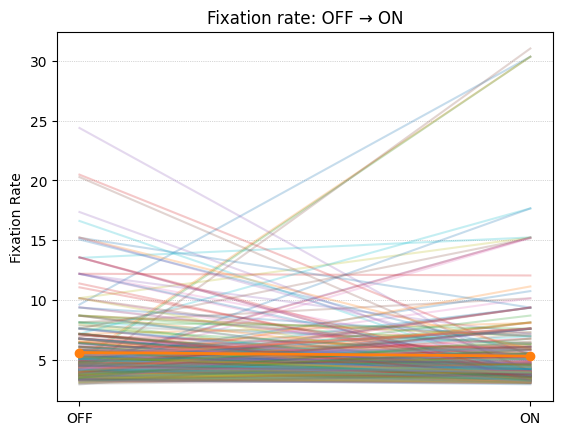

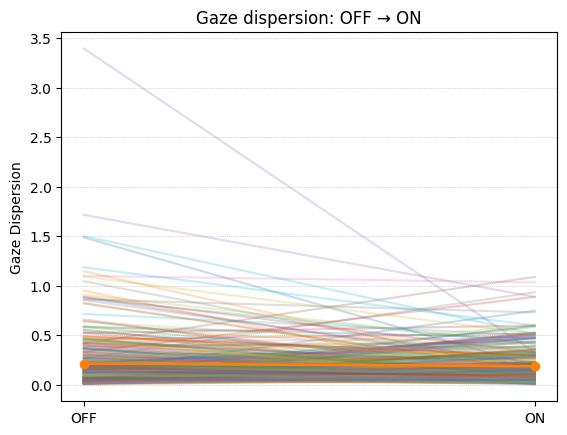

/var/folders/jh/6lrcqwz57w5_2ylmrnwyby_00000gn/T/ipykernel_50833/3723068636.py:49: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([off, on], labels=["OFF", "ON"], showmeans=True)


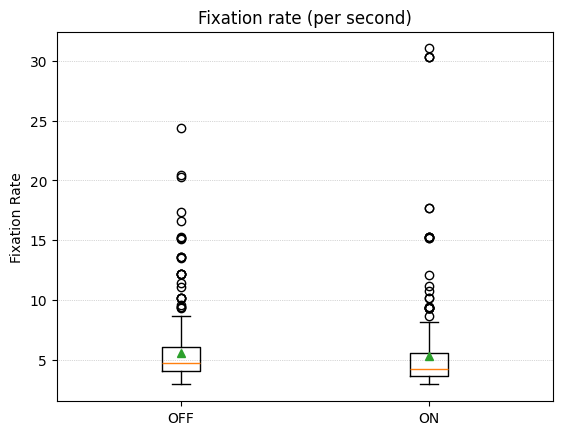

/var/folders/jh/6lrcqwz57w5_2ylmrnwyby_00000gn/T/ipykernel_50833/3723068636.py:49: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([off, on], labels=["OFF", "ON"], showmeans=True)


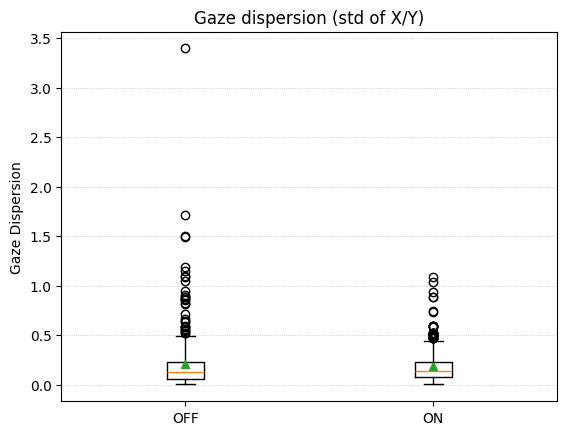

In [32]:
# 1) Quick numeric summaries
summ_fix = summarize_paired_metric(pairs_features, "fixation_rate")
summ_disp = summarize_paired_metric(pairs_features, "gaze_dispersion")

# 2) Paired line plots (OFF→ON per pair)
plot_paired_lines(pairs_features, "fixation_rate", title="Fixation rate: OFF → ON")
plot_paired_lines(pairs_features, "gaze_dispersion", title="Gaze dispersion: OFF → ON")

# 3) Boxplots (OFF vs ON)
plot_boxplot_off_on(pairs_features, "fixation_rate", title="Fixation rate (per second)")
plot_boxplot_off_on(pairs_features, "gaze_dispersion", title="Gaze dispersion (std of X/Y)")

During ON windows, participants made slightly fewer fixations per second compared to the 3 s OFF baseline. The difference is consistent enough to reach significance, but the effect size is tiny (practically negligible).

ON vs OFF shows no reliable change in dispersion of gaze points. Participants were equally spread out in their viewing patterns before and during animations.

In [33]:
def summarize_by_type(pairs_features, metric_base):
    """
    Summarize OFF→ON differences for a given metric, split by animation type.
    Returns a DataFrame with per-type stats.
    """
    from scipy.stats import wilcoxon
    import numpy as np
    import pandas as pd

    results = []
    for t, sub in pairs_features.groupby("type"):
        if f"{metric_base}_ON" not in sub or f"{metric_base}_OFF" not in sub:
            continue
        on  = sub[f"{metric_base}_ON"].to_numpy(dtype=float)
        off = sub[f"{metric_base}_OFF"].to_numpy(dtype=float)
        mask = np.isfinite(on) & np.isfinite(off)
        on, off = on[mask], off[mask]

        if len(on) == 0:
            continue

        diff = on - off
        mean_diff   = float(np.mean(diff))
        median_diff = float(np.median(diff))
        cohen_d     = float(mean_diff / np.std(diff, ddof=1)) if np.std(diff, ddof=1) > 0 else np.nan

        try:
            stat, p = wilcoxon(on, off, zero_method="wilcox", correction=False,
                               alternative="two-sided", mode="auto")
        except ValueError:
            stat, p = np.nan, np.nan

        results.append({
            "type": t,
            "metric": metric_base,
            "n_pairs": len(on),
            "mean_diff": mean_diff,
            "median_diff": median_diff,
            "cohen_d": cohen_d,
            "wilcoxon_p": p
        })

    return pd.DataFrame(results)

In [34]:
fix_rate_summary = summarize_by_type(pairs_features, "fixation_rate")
disp_summary     = summarize_by_type(pairs_features, "gaze_dispersion")

print("Fixation rate by animation type:")
print(fix_rate_summary)

print("\nGaze dispersion by animation type:")
print(disp_summary)

Fixation rate by animation type:
     type         metric  n_pairs  mean_diff  median_diff   cohen_d  \
0  BOUNCE  fixation_rate      125  -0.370884    -0.138046 -0.110598   
1    FADE  fixation_rate      105  -0.597253    -0.477176 -0.168186   
2  SCROLL  fixation_rate      121   0.026652    -0.376665  0.004564   

   wilcoxon_p  
0    0.206674  
1    0.027064  
2    0.052859  

Gaze dispersion by animation type:
     type           metric  n_pairs  mean_diff  median_diff   cohen_d  \
0  BOUNCE  gaze_dispersion      125   0.033422     0.041108  0.091525   
1    FADE  gaze_dispersion      105  -0.087679    -0.051583 -0.364363   
2  SCROLL  gaze_dispersion      121  -0.031625     0.000006 -0.122935   

   wilcoxon_p  
0    0.001331  
1    0.000643  
2    0.687524  


In [35]:
import matplotlib.pyplot as plt
import numpy as np

def plot_paired_by_type(pairs_features, metric_base, max_lines=300):
    """
    Paired line plots OFF→ON, split by animation type.
    metric_base: e.g., "fixation_rate" or "gaze_dispersion"
    """
    types = pairs_features["type"].dropna().unique()
    for t in types:
        sub = pairs_features[pairs_features["type"] == t]
        on  = sub[f"{metric_base}_ON"].to_numpy(dtype=float)
        off = sub[f"{metric_base}_OFF"].to_numpy(dtype=float)
        mask = np.isfinite(on) & np.isfinite(off)
        on, off = on[mask], off[mask]

        if len(on) == 0: 
            continue

        if len(on) > max_lines:
            idx = np.random.choice(len(on), size=max_lines, replace=False)
            on, off = on[idx], off[idx]

        plt.figure()
        for i in range(len(on)):
            plt.plot([0,1], [off[i], on[i]], color="gray", alpha=0.3)

        # Overlay mean ± SEM
        mean_off, mean_on = np.mean(off), np.mean(on)
        sem_off = np.std(off, ddof=1)/np.sqrt(len(off))
        sem_on  = np.std(on, ddof=1)/np.sqrt(len(on))
        plt.errorbar([0,1], [mean_off, mean_on], yerr=[sem_off, sem_on], fmt='o-', c="red", lw=2)

        plt.xticks([0,1], ["OFF","ON"])
        plt.ylabel(metric_base.replace("_"," ").title())
        plt.title(f"{metric_base.replace('_',' ').title()} (type={t})")
        plt.grid(True, axis='y', linestyle=':', lw=0.5)
        plt.show()

def plot_boxplot_by_type(pairs_features, metric_base):
    """
    Boxplots OFF vs ON split by animation type.
    """
    types = pairs_features["type"].dropna().unique()
    for t in types:
        sub = pairs_features[pairs_features["type"] == t]
        on  = sub[f"{metric_base}_ON"].to_numpy(dtype=float)
        off = sub[f"{metric_base}_OFF"].to_numpy(dtype=float)
        mask = np.isfinite(on) & np.isfinite(off)
        on, off = on[mask], off[mask]

        if len(on) == 0: 
            continue

        plt.figure()
        plt.boxplot([off, on], labels=["OFF","ON"], showmeans=True)
        plt.ylabel(metric_base.replace("_"," ").title())
        plt.title(f"{metric_base.replace('_',' ').title()} (type={t})")
        plt.grid(True, axis='y', linestyle=':', lw=0.5)
        plt.show()
        

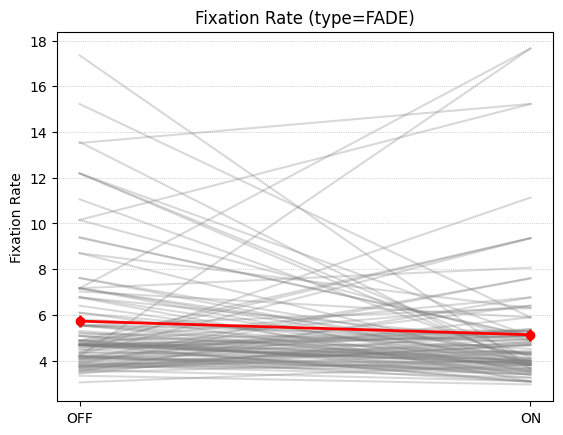

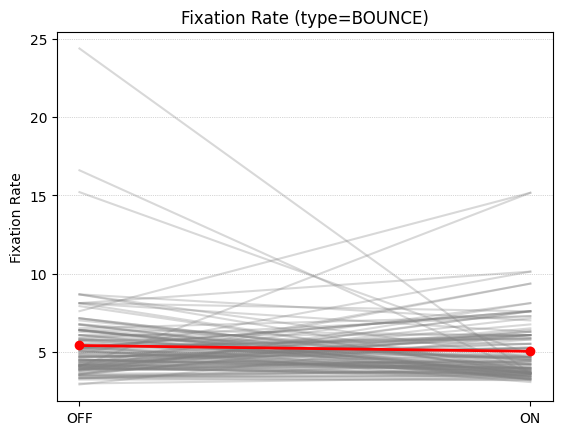

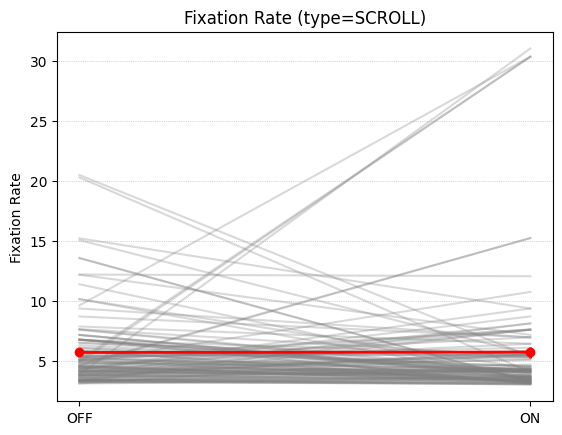

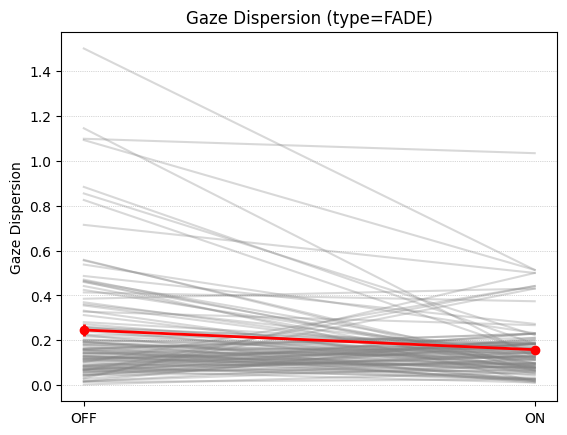

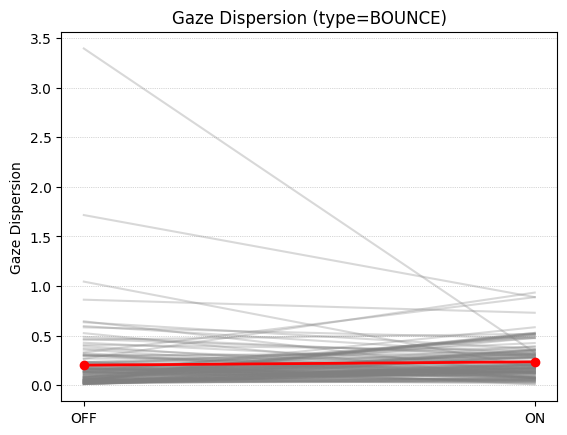

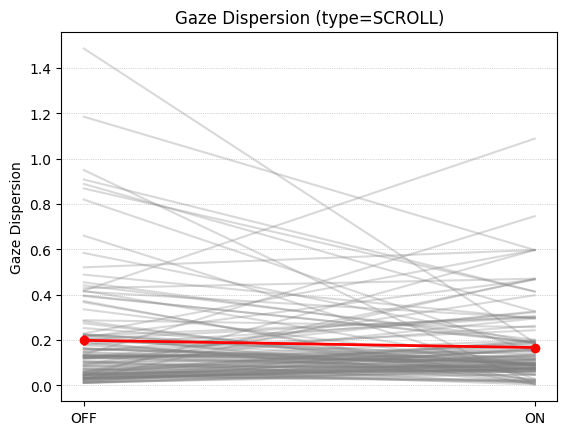

/var/folders/jh/6lrcqwz57w5_2ylmrnwyby_00000gn/T/ipykernel_50833/1076738284.py:56: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([off, on], labels=["OFF","ON"], showmeans=True)


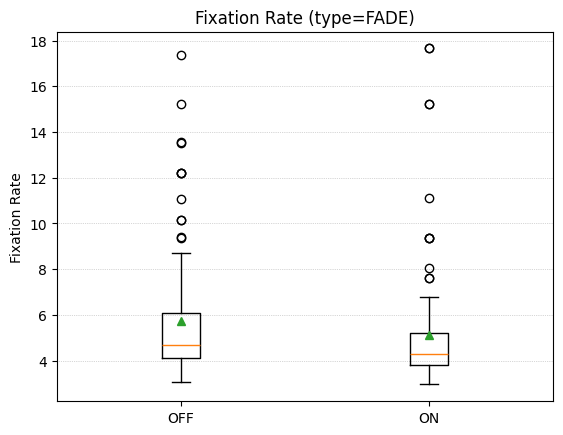

/var/folders/jh/6lrcqwz57w5_2ylmrnwyby_00000gn/T/ipykernel_50833/1076738284.py:56: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([off, on], labels=["OFF","ON"], showmeans=True)


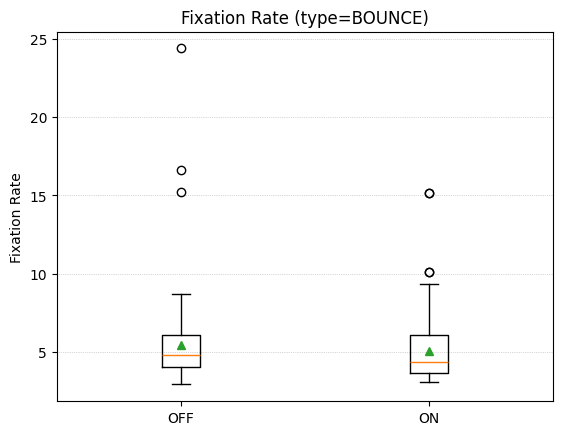

/var/folders/jh/6lrcqwz57w5_2ylmrnwyby_00000gn/T/ipykernel_50833/1076738284.py:56: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([off, on], labels=["OFF","ON"], showmeans=True)


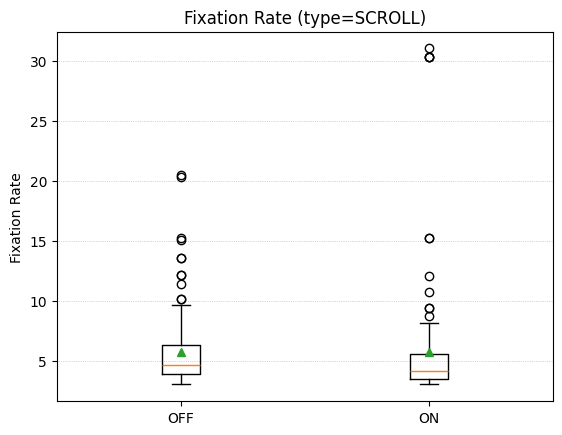

/var/folders/jh/6lrcqwz57w5_2ylmrnwyby_00000gn/T/ipykernel_50833/1076738284.py:56: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([off, on], labels=["OFF","ON"], showmeans=True)


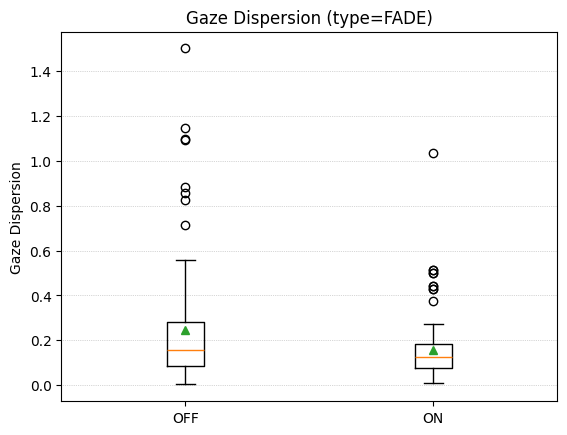

/var/folders/jh/6lrcqwz57w5_2ylmrnwyby_00000gn/T/ipykernel_50833/1076738284.py:56: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([off, on], labels=["OFF","ON"], showmeans=True)


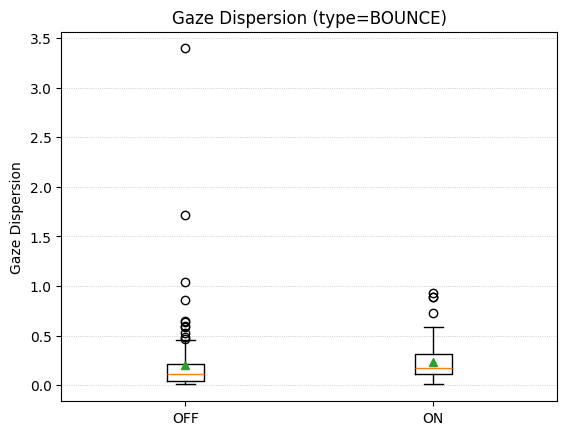

/var/folders/jh/6lrcqwz57w5_2ylmrnwyby_00000gn/T/ipykernel_50833/1076738284.py:56: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([off, on], labels=["OFF","ON"], showmeans=True)


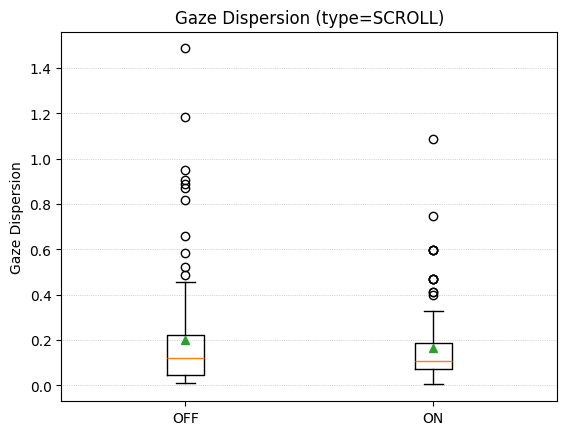

In [36]:
# Paired line plots
plot_paired_by_type(pairs_features, "fixation_rate")
plot_paired_by_type(pairs_features, "gaze_dispersion")

# Boxplots
plot_boxplot_by_type(pairs_features, "fixation_rate")
plot_boxplot_by_type(pairs_features, "gaze_dispersion")

# Comparing animation vs non-animation in tasks
i did this to see if there is higher quality information derivable


In [ ]:
# --- CONFIG ---
# Hardcode your "no animation" Task Ids here (strings).
NO_ANIM_TASK_IDS = {"1.4", "2.2", "3.9"} 

# Fixed analysis window relative to task start (seconds)
WINDOW_START = 0.0      # start at onset
WINDOW_DUR   = 2.0      # first 2 seconds

# --- REQUIRED INPUTS ---
# fixations_df: your all-rows fixations CSV already loaded
# tasks_all:    your mapping table with start/end times loaded
# decode_task:  your function that yields {"type": "..."} or {"animation": "..."}

def _aggregate_window(df: pd.DataFrame) -> pd.Series:
    """Time-normalized + simple gaze features."""
    if df.empty:
        return pd.Series({
            "fixation_rate": np.nan,
            "mean_fixation_duration": np.nan,
            "AOI_ratio": np.nan,
            "pupil_mean_L": np.nan,
            "pupil_mean_R": np.nan,
            "gaze_dispersion": np.nan,
            "n_samples": 0
        })

    tmin, tmax = df["TIME"].min(), df["TIME"].max()
    duration = float(tmax - tmin) if pd.notna(tmax) and pd.notna(tmin) and (tmax > tmin) else np.nan

    fix_count = df["FPOGID"].nunique() if "FPOGID" in df.columns else np.nan
    fixation_rate = (fix_count / duration) if (pd.notna(duration) and duration > 0) else np.nan

    gx_std = df["FPOGX"].std(skipna=True) if "FPOGX" in df.columns else np.nan
    gy_std = df["FPOGY"].std(skipna=True) if "FPOGY" in df.columns else np.nan
    gaze_dispersion = np.nanmean([gx_std, gy_std])

    return pd.Series({
        "fixation_rate": fixation_rate,
        "mean_fixation_duration": df["FPOGD"].mean(skipna=True) if "FPOGD" in df.columns else np.nan,
        "AOI_ratio": df["AOI"].notna().mean() if "AOI" in df.columns else np.nan,
        "pupil_mean_L": df["LPMM"].mean(skipna=True) if "LPMM" in df.columns else np.nan,
        "pupil_mean_R": df["RPMM"].mean(skipna=True) if "RPMM" in df.columns else np.nan,
        "gaze_dispersion": gaze_dispersion,
        "n_samples": len(df),
    })

def build_trial_features(
    fixations_df: pd.DataFrame,
    tasks_all: pd.DataFrame,
    no_anim_task_ids: set[str],
    window_start: float = WINDOW_START,
    window_dur: float = WINDOW_DUR,
) -> pd.DataFrame:
    """
    For each task, slice a fixed window after t_start and compute features.
    Labels each row as 'NO_ANIM' if Task Id ∈ no_anim_task_ids, else 'ANIM'.
    """
    # Normalize tasks table
    tasks = tasks_all.rename(columns={
        "Video Name": "Video Name (folder)",
        "User ID": "User ID (file)",
        "Starting time in seconds": "t_start",
        "Finishing time in seconds": "t_end",
    }).copy()

    for c in ["t_start", "t_end"]:
        tasks[c] = pd.to_numeric(tasks[c], errors="coerce")
    tasks = tasks.dropna(subset=["t_start"])

    tasks["Task Id"] = tasks["Task Id"].astype(str)
    fix = fixations_df.copy()
    fix["Task Id"] = fix["Task Id"].astype(str, errors="ignore")
    fix["TIME"] = pd.to_numeric(fix["TIME"], errors="coerce")

    rows = []
    for _, r in tasks.iterrows():
        vn, uid, tid, t0 = r["Video Name (folder)"], r["User ID (file)"], r["Task Id"], float(r["t_start"])

        w_start = t0 + float(window_start)
        w_end   = w_start + float(window_dur)

        mask = (
            (fix["Video Name (folder)"] == vn) &
            (fix["User ID (file)"] == uid) &
            (fix["Task Id"] == tid) &
            (fix["TIME"] >= w_start) & (fix["TIME"] <= w_end)
        )
        dfw = fix.loc[mask]
        feats = _aggregate_window(dfw)

        # animation labeling & type
        cond = "NO_ANIM" if tid in no_anim_task_ids else "ANIM"
        try:
            # Use your existing decoder (returns {"type": "..."} or {"animation": "..."})
            info = decode_task(tid)
            a_type = info.get("animation") or info.get("type") or "Unknown"
        except Exception:
            a_type = "Unknown"

        rows.append({
            "Video Name (folder)": vn,
            "User ID (file)": uid,
            "Task Id": tid,
            "type": a_type,
            "condition": cond,
            "win_start": w_start,
            "win_end": w_end,
            **feats.to_dict(),
        })

    return pd.DataFrame(rows)

def compare_anim_vs_noanim(trial_features: pd.DataFrame, metric: str, per_type: bool = False):
    """
    Compare ANIM vs NO_ANIM for a given metric.
    If per_type=True, prints stats per animation type.
    """
    def _summ(df):
        a = df.loc[df["condition"]=="ANIM", metric].dropna().to_numpy()
        n = df.loc[df["condition"]=="NO_ANIM", metric].dropna().to_numpy()
        out = {
            "n_anim": len(a), "n_noanim": len(n),
            "mean_anim": float(np.mean(a)) if len(a) else np.nan,
            "mean_noanim": float(np.mean(n)) if len(n) else np.nan,
        }
        # tests (fallback if one group too small)
        try:
            t_stat, t_p = ttest_ind(a, n, equal_var=False)
        except Exception:
            t_stat, t_p = np.nan, np.nan
        out["t_p"] = t_p

        # If you want a non-parametric alternative on unpaired groups, use Mann–Whitney:
        from scipy.stats import mannwhitneyu
        try:
            u_stat, u_p = mannwhitneyu(a, n, alternative="two-sided")
        except Exception:
            u_stat, u_p = np.nan, np.nan
        out["mw_p"] = u_p
        return out

    if per_type:
        res = []
        for t, sub in trial_features.groupby("type"):
            s = _summ(sub)
            s["type"] = t
            res.append(s)
        return pd.DataFrame(res).sort_values("type")

    return pd.DataFrame([_summ(trial_features)])

# ---------- RUN ----------
# 1) Build fixed-window features per trial
trial_features = build_trial_features(
    fixations_df=fixations_df,
    tasks_all=tasks_all,
    no_anim_task_ids=NO_ANIM_TASK_IDS,
    window_start=WINDOW_START,
    window_dur=WINDOW_DUR
)

# 2) Compare ANIM vs NO_ANIM overall
print("Overall — fixation_rate")
print(compare_anim_vs_noanim(trial_features, "fixation_rate"))

print("\nOverall — gaze_dispersion")
print(compare_anim_vs_noanim(trial_features, "gaze_dispersion"))

# 3) (Later) Split by animation type
print("\nPer-type — fixation_rate")
print(compare_anim_vs_noanim(trial_features, "fixation_rate", per_type=True))

print("\nPer-type — gaze_dispersion")
print(compare_anim_vs_noanim(trial_features, "gaze_dispersion", per_type=True))

# 4) (Optional) Save for plotting/inspection
# trial_features.to_csv("outputs/trial_features_anim_vs_noanim.csv", index=False)

/var/folders/jh/6lrcqwz57w5_2ylmrnwyby_00000gn/T/ipykernel_66113/628697595.py:39: RuntimeWarning: Mean of empty slice
  gaze_dispersion = np.nanmean([gx_std, gy_std])


Overall — fixation_rate
   n_anim  n_noanim  mean_anim  mean_noanim       t_p     mw_p
0     296        36   3.616698     3.637385  0.903089  0.59829

Overall — gaze_dispersion
   n_anim  n_noanim  mean_anim  mean_noanim       t_p     mw_p
0     296        36   0.220228     0.174718  0.128941  0.36803

Per-type — fixation_rate
   n_anim  n_noanim  mean_anim  mean_noanim       t_p     mw_p     type
0     296        36   3.616698     3.637385  0.903089  0.59829  Unknown

Per-type — gaze_dispersion
   n_anim  n_noanim  mean_anim  mean_noanim       t_p     mw_p     type
0     296        36   0.220228     0.174718  0.128941  0.36803  Unknown


In [4]:
import matplotlib.pyplot as plt

def plot_box_anim_vs_noanim(trial_features, metric, per_type=False):
    """
    Boxplot of Anim vs No-Anim for a metric.
    If per_type=True, plots grouped by animation type.
    """
    if not per_type:
        sub = trial_features.dropna(subset=[metric])
        groups = [sub.loc[sub["condition"]=="NO_ANIM", metric],
                  sub.loc[sub["condition"]=="ANIM", metric]]
        plt.figure()
        plt.boxplot(groups, labels=["No-Anim", "Anim"], showmeans=True)
        plt.ylabel(metric.replace("_"," ").title())
        plt.title(f"{metric.replace('_',' ').title()}: Anim vs No-Anim (all types)")
        plt.grid(axis="y", linestyle=":", linewidth=0.5)
        plt.show()
    else:
        for t, sub in trial_features.groupby("type"):
            sub = sub.dropna(subset=[metric])
            groups = [sub.loc[sub["condition"]=="NO_ANIM", metric],
                      sub.loc[sub["condition"]=="ANIM", metric]]
            if len(groups[0])==0 or len(groups[1])==0:
                continue
            plt.figure()
            plt.boxplot(groups, labels=["No-Anim", "Anim"], showmeans=True)
            plt.ylabel(metric.replace("_"," ").title())
            plt.title(f"{metric.replace('_',' ').title()}: {t}")
            plt.grid(axis="y", linestyle=":", linewidth=0.5)
            plt.show()

/var/folders/jh/6lrcqwz57w5_2ylmrnwyby_00000gn/T/ipykernel_66113/1587785109.py:13: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(groups, labels=["No-Anim", "Anim"], showmeans=True)


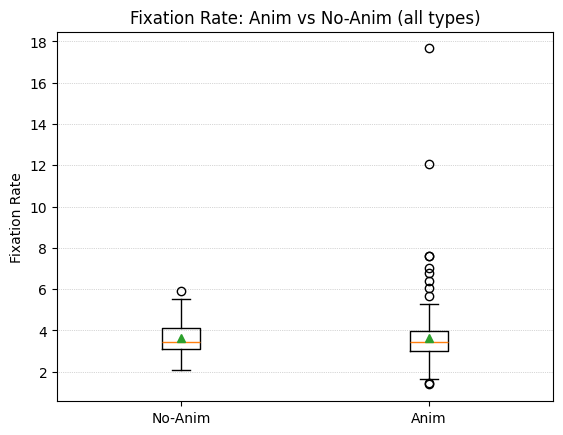

/var/folders/jh/6lrcqwz57w5_2ylmrnwyby_00000gn/T/ipykernel_66113/1587785109.py:13: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(groups, labels=["No-Anim", "Anim"], showmeans=True)


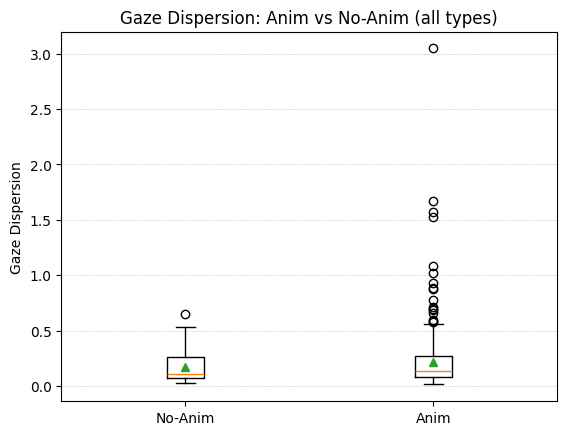

/var/folders/jh/6lrcqwz57w5_2ylmrnwyby_00000gn/T/ipykernel_66113/1587785109.py:26: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(groups, labels=["No-Anim", "Anim"], showmeans=True)


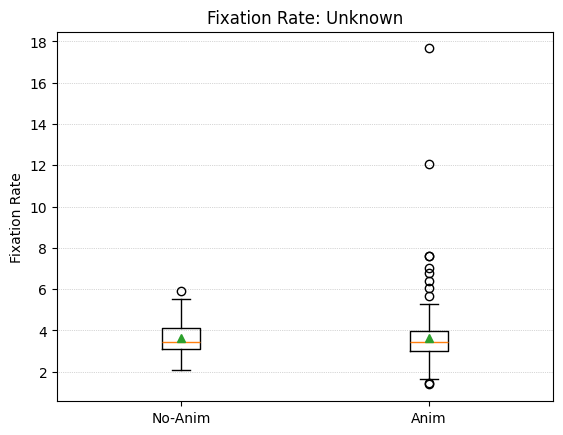

/var/folders/jh/6lrcqwz57w5_2ylmrnwyby_00000gn/T/ipykernel_66113/1587785109.py:26: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(groups, labels=["No-Anim", "Anim"], showmeans=True)


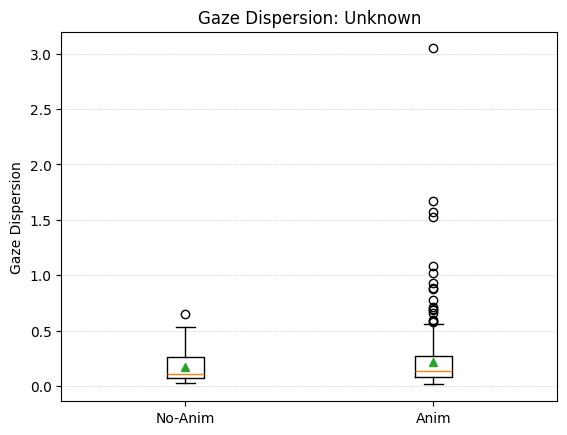

In [8]:
# Boxplots overall
plot_box_anim_vs_noanim(trial_features, "fixation_rate")
plot_box_anim_vs_noanim(trial_features, "gaze_dispersion")

# Boxplots per animation type
plot_box_anim_vs_noanim(trial_features, "fixation_rate", per_type=True)
plot_box_anim_vs_noanim(trial_features, "gaze_dispersion", per_type=True)
